# 08 — Modelado de clasificación (BD_IPSA_1940): logística L1/L2 y KNN

**Objetivo (enunciado del taller, Tarea 3):** clasificar Bajo/Medio/Alto de TCH y de sacarosa con **regresión logística
multinomial** (regularizada con L1/L2 para analizar la importancia y la selección de variables) y **KNN** con `k`
optimizado. Se reporta primero un benchmark simple.

**Diseño (decidido en los notebooks 04–07):**
- Split y CV **por hacienda** (agrupar por lote dejaba lotes de la misma hacienda y mes de cosecha a ambos lados del corte): `split_clasificacion` (test 438 filas, 56 haciendas) y `CV_CLF`
  (`StratifiedGroupKFold(5)` por hacienda, estratificado por la clase del target).
- Preprocesamiento: `construir_preprocesador_clf`. La logística usa todas las predictoras; KNN usa el conjunto
  reducido por target.
- **Métrica para elegir hiperparámetros: Kappa.** También se reportan Accuracy, Precision, Recall y F1 (macro) y
  el **recall de "Bajo"**. `class_weight="balanced"` en la logística; KNN no admite pesos por clase.
- Progresión: (0) benchmark, logística **sin** regularización; (1) logística L2; (2) logística L1; (3) KNN.
- **Advertencia:** C y `k` se eligen con la misma CV que se reporta, así que la media de CV del mejor valor es algo
  optimista. El hold-out (test) no participa en ninguna elección.

> **Alcance:** solo CC01-1940 madurada con BONUS 250 EC y cosechada a máquina. "Hacienda nueva" significa una
> hacienda no vista dentro de esta población.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, cohen_kappa_score, confusion_matrix, make_scorer
from sklearn.model_selection import GridSearchCV, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ))
from src.datos import CLASES, CV_CLF, TARGETS_CLASIFICACION, cargar_ipsa, preparar_xy_clf, split_clasificacion
from src.evaluacion import COLORES, evaluar_clf
from src.modelos_clasificacion import KNNPriorCorregido
from src.preprocesamiento_clasificacion import EXCLUIDAS_KNN, FLAG_LLUVIA, construir_preprocesador_clf

FIG_DIR = RAIZ / "reports" / "figures"
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
warnings.filterwarnings("ignore", category=ConvergenceWarning)

KAPPA = make_scorer(cohen_kappa_score)
GRILLA_C = np.logspace(-3, 2, 11)
GRILLA_K = list(range(1, 102, 2))

ipsa = cargar_ipsa()
train, test = split_clasificacion(ipsa)
print(f"Train {len(train):,} / Test {len(test):,} filas | haciendas {train['FAZ'].nunique()} / {test['FAZ'].nunique()}")

Train 1,749 / Test 438 filas | haciendas 229 / 56


## 1. Ajuste de hiperparámetros (solo train, CV por hacienda)

In [2]:
def logistica(**kw):
    return Pipeline([("pre", construir_preprocesador_clf("logistica")),
                     ("clf", LogisticRegression(max_iter=20000, class_weight="balanced", **kw))])

def knn(t):
    return Pipeline([("pre", construir_preprocesador_clf("knn", target=t)), ("clf", KNeighborsClassifier())])

datos, grillas, modelos = {}, {}, {}
for t in TARGETS_CLASIFICACION:
    X, y, g = preparar_xy_clf(train, t)
    X_te, y_te, _ = preparar_xy_clf(test, t)
    datos[t] = (X, y, g, X_te, y_te)
    grillas[t] = {
        "L2": GridSearchCV(logistica(l1_ratio=0), {"clf__C": GRILLA_C}, cv=CV_CLF, scoring=KAPPA).fit(X, y, groups=g),
        "L1": GridSearchCV(logistica(l1_ratio=1, solver="saga"), {"clf__C": GRILLA_C}, cv=CV_CLF, scoring=KAPPA).fit(X, y, groups=g),
        "KNN": GridSearchCV(knn(t), {"clf__n_neighbors": GRILLA_K}, cv=CV_CLF, scoring=KAPPA).fit(X, y, groups=g),
    }
    modelos[t] = {
        "Benchmark: logística sin regularización": logistica(C=np.inf),
        "Logística L2": grillas[t]["L2"].best_estimator_,
        "Logística L1": grillas[t]["L1"].best_estimator_,
        "KNN": grillas[t]["KNN"].best_estimator_,
    }
    print(f"{t}: C L2 = {grillas[t]['L2'].best_params_['clf__C']:.4g} | C L1 = {grillas[t]['L1'].best_params_['clf__C']:.4g} "
          f"| k = {grillas[t]['KNN'].best_params_['clf__n_neighbors']}")

TCH: C L2 = 0.1 | C L1 = 0.1 | k = 39


sacarosa: C L2 = 0.03162 | C L1 = 0.3162 | k = 29


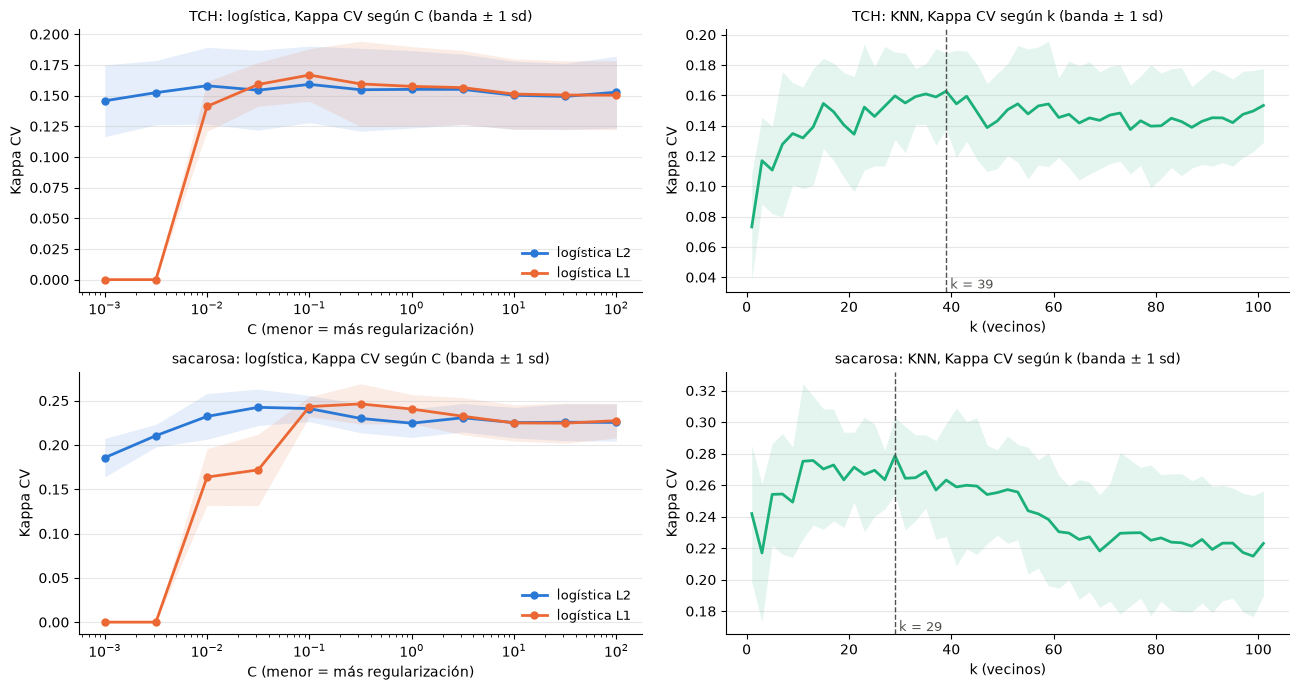

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for i, t in enumerate(TARGETS_CLASIFICACION):
    ax = axes[i, 0]
    for nombre, color in (("L2", COLORES["serie1"]), ("L1", COLORES["serie2"])):
        r = grillas[t][nombre].cv_results_
        ax.plot(GRILLA_C, r["mean_test_score"], marker="o", lw=2, ms=5, color=color, label=f"logística {nombre}")
        ax.fill_between(GRILLA_C, r["mean_test_score"] - r["std_test_score"], r["mean_test_score"] + r["std_test_score"],
                        color=color, alpha=0.12, lw=0)
    ax.set_xscale("log"); ax.set_xlabel("C (menor = más regularización)"); ax.set_ylabel("Kappa CV")
    ax.set_title(f"{t}: logística, Kappa CV según C (banda ± 1 sd)", fontsize=10); ax.legend(frameon=False, fontsize=9)
    ax = axes[i, 1]
    r = grillas[t]["KNN"].cv_results_
    ax.plot(GRILLA_K, r["mean_test_score"], lw=2, color=COLORES["serie3"])
    ax.fill_between(GRILLA_K, r["mean_test_score"] - r["std_test_score"], r["mean_test_score"] + r["std_test_score"],
                    color=COLORES["serie3"], alpha=0.12, lw=0)
    k_best = grillas[t]["KNN"].best_params_["clf__n_neighbors"]
    ax.axvline(k_best, color=COLORES["tinta"], lw=1, ls="--")
    ax.text(k_best, ax.get_ylim()[0], f" k = {k_best}", color=COLORES["tinta"], fontsize=9, va="bottom")
    ax.set_xlabel("k (vecinos)"); ax.set_ylabel("Kappa CV")
    ax.set_title(f"{t}: KNN, Kappa CV según k (banda ± 1 sd)", fontsize=10)
for ax in axes.ravel():
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "clf_hiperparametros.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. CV frente a hold-out (tabla consolidada)

`evaluar_clf` (`src/evaluacion.py`): CV por hacienda en train (media ± sd de los folds), después ajuste en todo train
y métricas en test. `brecha` = CV − test: si es muy positiva, hay sobreajuste o el test difiere de train.

In [4]:
resultados, ajustados, folds = [], {}, {}
for t in TARGETS_CLASIFICACION:
    X, y, g, X_te, y_te = datos[t]
    for nombre, modelo in modelos[t].items():
        r = evaluar_clf(modelo, X, y, g, X_te, y_te)
        ajustados[(t, nombre)] = r
        folds[(t, nombre)] = r["folds"]["test_Kappa"]
        resultados.append({"target": t, "modelo": nombre, **r["metricas"]})
tabla = pd.DataFrame(resultados).set_index(["target", "modelo"])
tabla.to_csv(RAIZ / "reports" / "resultados_clasificacion.csv")

vista = pd.DataFrame({
    "Kappa CV": tabla["Kappa_cv"].round(3).astype(str) + " ± " + tabla["Kappa_cv_sd"].round(3).astype(str),
    "Kappa test": tabla["Kappa_test"].round(3),
    "brecha Kappa": tabla["brecha_Kappa"].round(3),
    "F1 CV": tabla["F1_cv"].round(3), "F1 test": tabla["F1_test"].round(3),
    "Accuracy test": tabla["Accuracy_test"].round(3),
    "Precision test": tabla["Precision_test"].round(3), "Recall test": tabla["Recall_test"].round(3),
    "Recall Bajo CV": tabla["Recall_Bajo_cv"].round(3), "Recall Bajo test": tabla["Recall_Bajo_test"].round(3),
})
display(vista)

Kappa CV  Kappa test  brecha Kappa  F1 CV  F1 test  Accuracy test  Precision test  Recall test  Recall Bajo CV  Recall Bajo test
target   modelo                                                                                                                                                                        
TCH      Benchmark: logística sin regularización  0.149 ± 0.025       0.114         0.034  0.425    0.392          0.402           0.424        0.412           0.489             0.475
         Logística L2                             0.159 ± 0.031       0.111         0.049  0.426    0.383          0.400           0.413        0.411           0.494             0.475
         Logística L1                             0.167 ± 0.021       0.093         0.074  0.428    0.384          0.395           0.390        0.405           0.494             0.465
         KNN                                      0.163 ± 0.025       0.107         0.055  0.412    0.403          0.436           0.434        0.404           0.118             0.198
sacarosa Benchmark: logística sin regularización  0.219 ± 0.016       0.221        -0.002  0.452    0.458          0.505           0.475        0.480           0.602             0.426
         Logística L2                             0.242 ± 0.021       0.231         0.012  0.476    0.464          0.509           0.473        0.485           0.626             0.436
         Logística L1                             0.246 ± 0.023       0.250        -0.004  0.478    0.483          0.521           0.488        0.500           0.618             0.457
         KNN                                      0.279 ± 0.024       0.237         0.042  0.511    0.470          0.530           0.522        0.475           0.350             0.223

## 3. L1 frente al EDA (¿anula L1 las variables que el EDA marcó como poco informativas?)

Se reporta: (a) si L1 anula (coeficiente = 0 en **todas** las clases y columnas) las variables que el EDA marcó como
candidatas, y (b) el **orden de salida** de las variables a lo largo del camino de regularización (C decreciente),
ajustando sobre todo train con el preprocesador de la logística. Para variables con varias columnas (dummies, bases
del spline) se usa el máximo |coeficiente|.

In [5]:
BASE = ["lluvias", FLAG_LLUVIA, "dosismad", "edad", "cortes", "anio", "semsmad", "grupo_tenencia", "mes_cosecha"]
origen = lambda c: next(v for v in BASE if c == v or c.startswith(v + "_"))

def coef_por_variable(pipe):
    cols = pipe.named_steps["pre"].get_feature_names_out()
    coef = pd.DataFrame(pipe.named_steps["clf"].coef_, columns=cols)
    return coef.abs().T.groupby([origen(c) for c in cols]).max().max(axis=1)

CAMINO_C = [0.3162, 0.1, 0.0562, 0.0316, 0.0178, 0.01]
for t in TARGETS_CLASIFICACION:
    l1 = ajustados[(t, "Logística L1")]["modelo"]
    magnitud = coef_por_variable(l1).sort_values()
    anuladas = set(magnitud[magnitud == 0].index)
    candidatas = EXCLUIDAS_KNN[t]
    print(f"== {t} (C óptimo = {l1.named_steps['clf'].C:.4g})")
    print("   max |coef| por variable:", magnitud.round(3).to_dict())
    print(f"   anuladas por L1: {sorted(anuladas) or 'ninguna'} | candidatas del EDA: {sorted(candidatas)}")
    print(f"   coinciden: {sorted(anuladas & candidatas) or 'ninguna'} | candidatas no anuladas: {sorted(candidatas - anuladas) or 'ninguna'} "
          f"| anuladas que no eran candidatas: {sorted(anuladas - candidatas) or 'ninguna'}")
    X, y, _, _, _ = datos[t]
    activas_prev, salida = set(BASE), {}
    for C in CAMINO_C:
        m = clone(l1).set_params(clf__C=C).fit(X, y)
        activas = set(v for v, a in coef_por_variable(m).items() if a > 0)
        for v in activas_prev - activas:
            salida[v] = C
        activas_prev = activas
    orden = sorted(BASE, key=lambda v: -salida.get(v, 0))
    print("   orden de salida (C en que la variable queda en 0; '—' = sigue activa con C = 0.01):")
    print("   " + " → ".join(f"{v}{'*' if v in candidatas else ''} ({salida[v]:g})" if v in salida else f"{v}{'*' if v in candidatas else ''} (—)" for v in orden))
print("* = candidata del EDA")

== TCH (C óptimo = 0.1)
   max |coef| por variable: {'lluvias': 0.057, 'semsmad': 0.06, 'dosismad': 0.063, 'falta_dato_lluvia': 0.066, 'edad': 0.071, 'mes_cosecha': 0.09, 'anio': 0.113, 'cortes': 0.476, 'grupo_tenencia': 0.56}
   anuladas por L1: ninguna | candidatas del EDA: ['dosismad', 'mes_cosecha', 'semsmad']
   coinciden: ninguna | candidatas no anuladas: ['dosismad', 'mes_cosecha', 'semsmad'] | anuladas que no eran candidatas: ninguna


   orden de salida (C en que la variable queda en 0; '—' = sigue activa con C = 0.01):
   falta_dato_lluvia (0.0562) → semsmad* (0.0562) → mes_cosecha* (0.0562) → dosismad* (0.0316) → lluvias (0.0178) → edad (0.01) → anio (0.01) → grupo_tenencia (0.01) → cortes (—)
== sacarosa (C óptimo = 0.3162)
   max |coef| por variable: {'falta_dato_lluvia': 0.019, 'cortes': 0.076, 'dosismad': 0.079, 'anio': 0.112, 'grupo_tenencia': 0.112, 'edad': 0.136, 'lluvias': 0.195, 'mes_cosecha': 1.344, 'semsmad': 1.629}
   anuladas por L1: ninguna | candidatas del EDA: ['cortes', 'falta_dato_lluvia', 'grupo_tenencia']
   coinciden: ninguna | candidatas no anuladas: ['cortes', 'falta_dato_lluvia', 'grupo_tenencia'] | anuladas que no eran candidatas: ninguna


   orden de salida (C en que la variable queda en 0; '—' = sigue activa con C = 0.01):
   falta_dato_lluvia* (0.1) → grupo_tenencia* (0.0562) → dosismad (0.0316) → edad (0.0178) → cortes* (0.0178) → anio (0.0178) → semsmad (0.0178) → mes_cosecha (0.01) → lluvias (—)
* = candidata del EDA


## 4. Coeficientes de la logística elegida (interpretación)

Se muestran los coeficientes de la logística con mejor Kappa CV de cada target, por clase (multinomial). Las
numéricas están estandarizadas: el coeficiente es el cambio en el logit de la clase por 1 sd. Para `semsmad`
(spline), `mes_cosecha` y `grupo_tenencia` (dummies contra la referencia: mes 1 y grupo 1), el efecto se lee por
columna.

In [6]:
for t in TARGETS_CLASIFICACION:
    candidatos = ["Logística L2", "Logística L1"]
    mejor = max(candidatos, key=lambda n: tabla.loc[(t, n), "Kappa_cv"])
    pipe = ajustados[(t, mejor)]["modelo"]
    cols = pipe.named_steps["pre"].get_feature_names_out()
    coef = pd.DataFrame(pipe.named_steps["clf"].coef_, index=pipe.named_steps["clf"].classes_, columns=cols).T[CLASES]
    print(f"== {t}: {mejor} (C = {pipe.named_steps['clf'].C:.4g}); numéricas y flags ordenados por |coef| de 'Alto'")
    simples = [c for c in cols if not c.startswith(("semsmad_sp", "mes_cosecha_", "grupo_tenencia_"))]
    display(coef.loc[simples].reindex(coef.loc[simples, "Alto"].abs().sort_values(ascending=False).index).round(3))
    print("   mes_cosecha (contra enero), coeficiente de 'Alto':",
          coef.filter(like="mes_cosecha_", axis=0)["Alto"].round(2).to_dict())
    print("   grupo_tenencia (contra 1), coeficiente de 'Alto':", coef.filter(like="grupo_tenencia_", axis=0)["Alto"].round(2).to_dict())

== TCH: Logística L1 (C = 0.1); numéricas y flags ordenados por |coef| de 'Alto'


,Bajo,Medio,Alto
cortes,0.147,0.000,-0.476
anio,0.061,0.000,-0.113
dosismad,0.000,-0.022,0.063
edad,0.000,-0.071,0.062
lluvias,-0.057,0.000,0.053
falta_dato_lluvia,0.066,-0.053,0.000


   mes_cosecha (contra enero), coeficiente de 'Alto': {'mes_cosecha_2': 0.0, 'mes_cosecha_3': 0.0, 'mes_cosecha_4': 0.0, 'mes_cosecha_5': 0.0, 'mes_cosecha_6': 0.0, 'mes_cosecha_7': 0.0, 'mes_cosecha_8': 0.0, 'mes_cosecha_9': 0.0, 'mes_cosecha_10': 0.0, 'mes_cosecha_11': 0.0, 'mes_cosecha_12': 0.0}
   grupo_tenencia (contra 1), coeficiente de 'Alto': {'grupo_tenencia_2': -0.28, 'grupo_tenencia_3': 0.11}
== sacarosa: Logística L1 (C = 0.3162); numéricas y flags ordenados por |coef| de 'Alto'


,Bajo,Medio,Alto
lluvias,0.195,0.000,-0.151
cortes,-0.076,0.000,0.030
anio,-0.112,0.000,0.022
falta_dato_lluvia,0.014,0.000,-0.019
edad,0.136,0.000,0.000
dosismad,-0.079,0.031,0.000


   mes_cosecha (contra enero), coeficiente de 'Alto': {'mes_cosecha_2': 0.0, 'mes_cosecha_3': 0.61, 'mes_cosecha_4': -0.56, 'mes_cosecha_5': -0.71, 'mes_cosecha_6': -0.81, 'mes_cosecha_7': -0.8, 'mes_cosecha_8': 0.0, 'mes_cosecha_9': 0.66, 'mes_cosecha_10': 0.87, 'mes_cosecha_11': 0.18, 'mes_cosecha_12': -0.17}
   grupo_tenencia (contra 1), coeficiente de 'Alto': {'grupo_tenencia_2': 0.11, 'grupo_tenencia_3': 0.0}


## 5. Sensibilidades de sacarosa (con la logística elegida)

(a) **Spline de `edad`** [12, 13, 15] frente a edad lineal, con la **regla de promoción**: Δ Kappa (promedio sobre los
mismos 5 folds) > sd de los 5 Kappa del lineal. Si F1 y Kappa no coinciden, decide Kappa. (b) **Tasa de lluvia**
(mm/mes de la ventana inferida del mes 10) en lugar de la suma: se reporta, no hay regla de promoción (depende de
un supuesto no confirmado).

In [7]:
t = "sacarosa"
X, y, g, X_te, y_te = datos[t]
mejor = max(["Logística L2", "Logística L1"], key=lambda n: tabla.loc[(t, n), "Kappa_cv"])
base_pipe = modelos[t][mejor]
clf_params = base_pipe.named_steps["clf"].get_params()
variantes = {
    "edad lineal (principal)": base_pipe,
    "edad spline [12, 13, 15]": Pipeline([("pre", construir_preprocesador_clf("logistica", edad_spline=True)),
                                           ("clf", LogisticRegression(**clf_params))]),
    "tasa de lluvia (mm/mes)": Pipeline([("pre", construir_preprocesador_clf("logistica", tasa_lluvia=True)),
                                          ("clf", LogisticRegression(**clf_params))]),
}
sens, kappas_fold, f1_fold = [], {}, {}
for nombre, m in variantes.items():
    r = evaluar_clf(m, X, y, g, X_te, y_te)
    kappas_fold[nombre], f1_fold[nombre] = r["folds"]["test_Kappa"], r["folds"]["test_F1"]
    sens.append({"variante": nombre, "Kappa CV": r["metricas"]["Kappa_cv"], "Kappa sd": r["metricas"]["Kappa_cv_sd"],
                 "F1 CV": r["metricas"]["F1_cv"], "Kappa test": r["metricas"]["Kappa_test"], "F1 test": r["metricas"]["F1_test"]})
display(pd.DataFrame(sens).set_index("variante").round(3))

d_k = (kappas_fold["edad spline [12, 13, 15]"] - kappas_fold["edad lineal (principal)"]).mean()
d_f = (f1_fold["edad spline [12, 13, 15]"] - f1_fold["edad lineal (principal)"]).mean()
sd_lineal = kappas_fold["edad lineal (principal)"].std()
promover = d_k > sd_lineal
print(f"Regla de promoción del spline ({mejor}): Δ Kappa = {d_k:+.3f} frente a sd del lineal = {sd_lineal:.3f} → "
      f"{'SE PROMUEVE' if promover else 'no se promueve'} | Δ F1 = {d_f:+.3f}"
      + (" (F1 y Kappa discrepan en el signo: decide Kappa)" if np.sign(d_k) != np.sign(d_f) else ""))

,Kappa CV,Kappa sd,F1 CV,Kappa test,F1 test
variante,,,,,
edad lineal (principal),0.246,0.023,0.478,0.250,0.483
"edad spline [12, 13, 15]",0.232,0.015,0.468,0.268,0.495
tasa de lluvia (mm/mes),0.245,0.016,0.478,0.251,0.480


Regla de promoción del spline (Logística L1): Δ Kappa = -0.014 frente a sd del lineal = 0.023 → no se promueve | Δ F1 = -0.010


## 6. Matrices de confusión en test

Filas: clase real; columnas: clase predicha. Valores normalizados por fila (recall de cada clase).

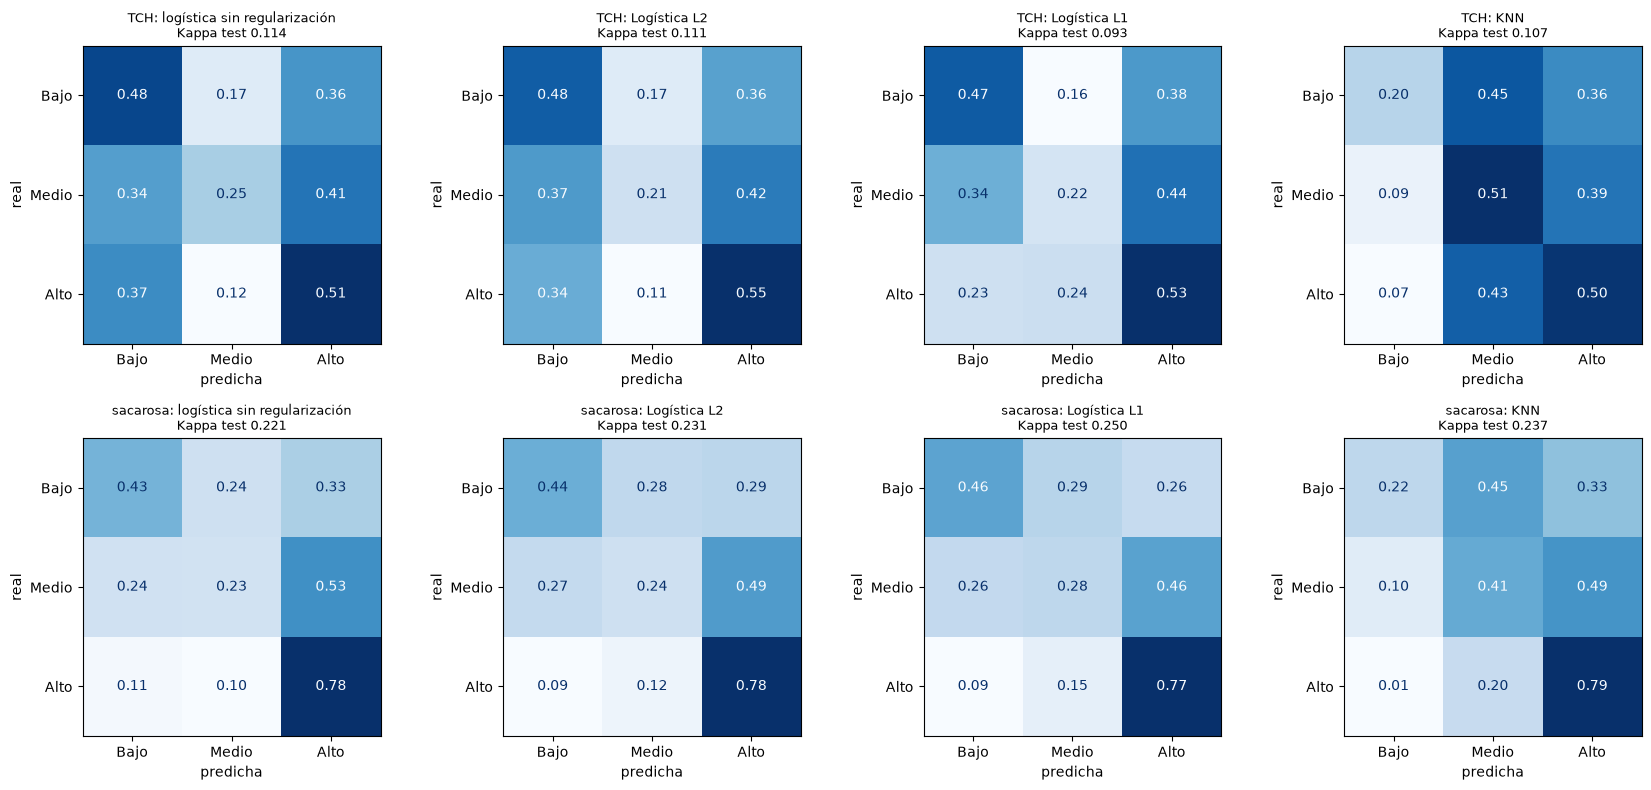

Recall por clase en test:


Bajo  Medio   Alto
target   modelo                                                      
TCH      Benchmark: logística sin regularización  0.475  0.253  0.509
         Logística L2                             0.475  0.206  0.551
         Logística L1                             0.465  0.224  0.527
         KNN                                      0.198  0.512  0.503
sacarosa Benchmark: logística sin regularización  0.426  0.231  0.783
         Logística L2                             0.436  0.238  0.783
         Logística L1                             0.457  0.275  0.766
         KNN                                      0.223  0.412  0.788

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for i, t in enumerate(TARGETS_CLASIFICACION):
    _, _, _, _, y_te = datos[t]
    for j, nombre in enumerate(modelos[t]):
        ax = axes[i, j]
        ConfusionMatrixDisplay.from_predictions(y_te, ajustados[(t, nombre)]["y_pred_test"], labels=CLASES,
                                                normalize="true", values_format=".2f", cmap="Blues", colorbar=False, ax=ax)
        ax.set_title(f"{t}: {nombre.replace('Benchmark: ', '')}\nKappa test {tabla.loc[(t, nombre), 'Kappa_test']:.3f}", fontsize=9)
        ax.set_xlabel("predicha"); ax.set_ylabel("real")
fig.tight_layout()
fig.savefig(FIG_DIR / "clf_matrices_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

print("Recall por clase en test:")
filas = []
for (t, nombre), r in ajustados.items():
    _, _, _, _, y_te = datos[t]
    cm = confusion_matrix(y_te, r["y_pred_test"], labels=CLASES)
    filas.append({"target": t, "modelo": nombre, **dict(zip(CLASES, (cm.diagonal() / cm.sum(axis=1)).round(3)))})
display(pd.DataFrame(filas).set_index(["target", "modelo"]))

## 7. Verificaciones antes de la elección final

**(1) ¿L1 sigue siendo preferible al benchmark en TCH?** Kappa por fold sobre los **mismos 5 folds** de esta CV (por
hacienda), diferencia pareada y bootstrap **por hacienda** del test (2 000 réplicas) para la diferencia de Kappa.

**(2) ¿Se descartó KNN por una comparación desigual?** La logística usa `class_weight="balanced"` y KNN no tenía ningún
mecanismo de balanceo. Se prueban `weights="distance"` y la **corrección por priors** (`KNNPriorCorregido`, el
análogo de `class_weight`), reoptimizando `k` en cada variante con la misma CV.

In [9]:
t = "TCH"
X, y, g, X_te, y_te = datos[t]
comparar = ["Benchmark: logística sin regularización", "Logística L2", "Logística L1"]
por_fold = pd.DataFrame({n: folds[(t, n)] for n in comparar}, index=[f"fold {i}" for i in range(5)])
resumen = pd.DataFrame({"media": por_fold.mean(), "sd (ddof=0)": por_fold.std(ddof=0), "sd (ddof=1)": por_fold.std(ddof=1)}).T
display(pd.concat([por_fold, resumen]).round(4))
d_par = por_fold["Logística L1"] - por_fold[comparar[0]]
print(f"Δ pareado L1 − benchmark por fold: {d_par.round(3).tolist()} → media {d_par.mean():+.4f}, sd {d_par.std(ddof=1):.4f} "
      f"(L1 gana en {(d_par > 0).sum()} de 5 folds)")

pred_l1 = ajustados[(t, "Logística L1")]["y_pred_test"]
pred_b = ajustados[(t, comparar[0])]["y_pred_test"]
d_test = cohen_kappa_score(y_te, pred_l1) - cohen_kappa_score(y_te, pred_b)
haciendas = test["FAZ"].to_numpy()
indices = {h: np.where(haciendas == h)[0] for h in np.unique(haciendas)}
rng = np.random.default_rng(42)
boot = []
for _ in range(2000):
    s = np.concatenate([indices[h] for h in rng.choice(list(indices), len(indices))])
    boot.append(cohen_kappa_score(y_te.iloc[s], pred_l1[s]) - cohen_kappa_score(y_te.iloc[s], pred_b[s]))
boot = np.array(boot)
print(f"Test: Δ Kappa L1 − benchmark = {d_test:+.4f} | sd de Kappa de L1 en los folds = {por_fold['Logística L1'].std(ddof=0):.4f} (ddof=0) / "
      f"{por_fold['Logística L1'].std(ddof=1):.4f} (ddof=1) | bootstrap por hacienda: sd {boot.std():.4f}, "
      f"IC95 [{np.quantile(boot, 0.025):+.3f}, {np.quantile(boot, 0.975):+.3f}]")

,Benchmark: logística sin regularización,Logística L2,Logística L1
fold 0,0.1779,0.1898,0.1878
fold 1,0.1198,0.1281,0.1497
fold 2,0.1431,0.1451,0.1705
fold 3,0.1251,0.1298,0.1353
fold 4,0.1771,0.2028,0.1903
media,0.1486,0.1591,0.1667
sd (ddof=0),0.0248,0.0312,0.0214
sd (ddof=1),0.0278,0.0349,0.0239


Δ pareado L1 − benchmark por fold: [0.01, 0.03, 0.027, 0.01, 0.013] → media +0.0181, sd 0.0098 (L1 gana en 5 de 5 folds)


Test: Δ Kappa L1 − benchmark = -0.0215 | sd de Kappa de L1 en los folds = 0.0214 (ddof=0) / 0.0239 (ddof=1) | bootstrap por hacienda: sd 0.0399, IC95 [-0.085, +0.065]


In [10]:
knn_variantes, filas = {}, []
for t in TARGETS_CLASIFICACION:
    X, y, g, X_te, y_te = datos[t]
    for pesos in ("uniform", "distance"):
        for prior in (False, True):
            clf = KNNPriorCorregido(weights=pesos) if prior else KNeighborsClassifier(weights=pesos)
            pipe = Pipeline([("pre", construir_preprocesador_clf("knn", target=t)), ("clf", clf)])
            gs = GridSearchCV(pipe, {"clf__n_neighbors": GRILLA_K}, cv=CV_CLF, scoring=KAPPA).fit(X, y, groups=g)
            nombre = f"KNN {pesos}{' + priors' if prior else ''}"
            r = evaluar_clf(gs.best_estimator_, X, y, g, X_te, y_te)
            knn_variantes[(t, nombre)] = r
            m = r["metricas"]
            filas.append({"target": t, "variante": nombre, "k": gs.best_params_["clf__n_neighbors"],
                          "Kappa CV": m["Kappa_cv"], "Kappa sd": m["Kappa_cv_sd"], "Kappa test": m["Kappa_test"],
                          "F1 test": m["F1_test"], "Recall Bajo CV": m["Recall_Bajo_cv"], "Recall Bajo test": m["Recall_Bajo_test"]})
    l1 = tabla.loc[(t, "Logística L1")]
    filas.append({"target": t, "variante": "(ref.) Logística L1", "k": np.nan, "Kappa CV": l1["Kappa_cv"],
                  "Kappa sd": l1["Kappa_cv_sd"], "Kappa test": l1["Kappa_test"], "F1 test": l1["F1_test"],
                  "Recall Bajo CV": l1["Recall_Bajo_cv"], "Recall Bajo test": l1["Recall_Bajo_test"]})
knn_tabla = pd.DataFrame(filas).set_index(["target", "variante"]).round(3)
display(knn_tabla)
extra = pd.DataFrame([{"target": t, "modelo": n, **r["metricas"]} for (t, n), r in knn_variantes.items()]).set_index(["target", "modelo"])
pd.concat([tabla, extra]).to_csv(RAIZ / "reports" / "resultados_clasificacion.csv")

k  Kappa CV  Kappa sd  Kappa test  F1 test  Recall Bajo CV  Recall Bajo test
target   variante                                                                                              
TCH      KNN uniform            39.0     0.163     0.025       0.107    0.403           0.118             0.198
         KNN uniform + priors   47.0     0.180     0.042       0.110    0.405           0.466             0.475
         KNN distance           39.0     0.175     0.029       0.110    0.411           0.144             0.248
         KNN distance + priors  47.0     0.175     0.024       0.115    0.407           0.454             0.475
         (ref.) Logística L1     NaN     0.167     0.021       0.093    0.384           0.494             0.465
sacarosa KNN uniform            29.0     0.279     0.024       0.237    0.470           0.350             0.223
         KNN uniform + priors   11.0     0.284     0.045       0.277    0.514           0.608             0.436
         KNN distance           35.0     0.303     0.031       0.240    0.475           0.345             0.234
         KNN distance + priors  23.0     0.303     0.025       0.289    0.523           0.613             0.468
         (ref.) Logística L1     NaN     0.246     0.023       0.250    0.483           0.618             0.457

In [11]:
# Bootstrap por hacienda de la diferencia de Kappa en prueba entre KNN con corrección (elegido) y la logística L1 en TCH.
# Mismo procedimiento que el intervalo L1 − benchmark de la celda anterior: 2 000 réplicas, haciendas de prueba
# remuestreadas con reemplazo y semilla 42.
t = "TCH"
_, _, _, _, y_te = datos[t]
pred_knn = knn_variantes[(t, "KNN distance + priors")]["y_pred_test"]
pred_l1 = ajustados[(t, "Logística L1")]["y_pred_test"]
d_knn = cohen_kappa_score(y_te, pred_knn) - cohen_kappa_score(y_te, pred_l1)
rng = np.random.default_rng(42)
boot_knn = []
for _ in range(2000):
    s = np.concatenate([indices[h] for h in rng.choice(list(indices), len(indices))])
    boot_knn.append(cohen_kappa_score(y_te.iloc[s], pred_knn[s]) - cohen_kappa_score(y_te.iloc[s], pred_l1[s]))
boot_knn = np.array(boot_knn)
print(f"TCH, prueba: Kappa KNN con corrección {cohen_kappa_score(y_te, pred_knn):.3f} | L1 {cohen_kappa_score(y_te, pred_l1):.3f} | "
      f"Δ = {d_knn:+.3f} | bootstrap por hacienda: IC95 [{np.quantile(boot_knn, 0.025):+.3f}, {np.quantile(boot_knn, 0.975):+.3f}]")

TCH, prueba: Kappa KNN con corrección 0.115 | L1 0.093 | Δ = +0.022 | bootstrap por hacienda: IC95 [-0.029, +0.085]


## 8. Conclusiones

**Elección final:**
- **TCH: logística L1 (C = 0.1), modelo único.** Le gana al benchmark en los 5 folds de CV. La caída en test es ruido
  (bootstrap por hacienda: IC95 [−0.085, +0.065]). KNN corregido es equivalente dentro del ruido, así que se prefiere
  el modelo interpretable.
- **Sacarosa: KNN distance + corrección por priors (k = 23) para predecir** (Kappa CV 0.303, test 0.289, F1 test 0.523,
  recall de "Bajo" 0.47) **y logística L1 (C = 0.32) para interpretar.** La ventaja de KNN se confirma en un test que
  no participó en la elección.
- **Comparación desigual corregida:** la primera lectura (abajo) descartaba KNN por su recall de "Bajo", pero era una comparación
  **desigual**: la logística balanceaba clases y KNN no. Con la corrección por priors (§7), KNN iguala ese recall.

*Registro de la primera lectura (antes de §7). La lectura de negocio de la logística L1 sigue vigente:*


**Desempeño general.** Los dos problemas son difíciles con predictoras conocidas antes de cosechar, en una hacienda
no vista. **Sacarosa:** Kappa ≈ 0.25 (acuerdo débil-moderado), estable entre CV y test. **TCH:** Kappa CV ≈ 0.15–0.17
y en test ≈ 0.09–0.11 (acuerdo débil). Es coherente con regresión, donde el R² de TCH también cae más al agrupar por
hacienda: el TCH depende de factores de la hacienda que las predictoras no capturan.

**TCH: el test es peor que la CV en todos los modelos, también en el benchmark sin ajuste** (brecha 0.03–0.07). Como
el benchmark no tiene hiperparámetros, la brecha no viene del ajuste de C o `k`: las 56 haciendas de test son más
difíciles que el promedio de los folds. Las diferencias entre modelos (≤ 0.02 de Kappa CV) están dentro de 1 sd.

**Regularización.** L1/L2 mejoran poco sobre el benchmark (+0.01–0.03 de Kappa CV), igual que Ridge/Lasso en
regresión: con ~1 700 filas y 26 columnas el error viene del sesgo, no de la varianza.

**KNN frente a la logística.** En sacarosa, KNN tiene el mejor Kappa CV (0.279 frente a 0.246, ~1.4 sd), pero en test
baja a 0.237 (brecha 0.042) y su **recall de "Bajo" colapsa a 0.22** (0.20 en TCH), frente a 0.46–0.48 de la
logística. KNN no tiene pesos por clase: favorece "Medio" (recall 0.41–0.51) y casi no predice "Bajo", justo la clase
que el Ingenio más necesita detectar (no detectarla es el error más costoso).

**Clase "Medio".** Como era de esperar, en la logística es la clase más confundida (recall 0.21–0.28): limita con
las dos clases extremas y su ancho (25 t/ha; 0.8 puntos) es menor que el error típico.

**L1 frente al EDA.** Con el C óptimo, L1 **no anula ninguna variable** en ninguno de los dos targets, así
que el criterio estricto no se cumple. El **orden de salida** sí coincide con el EDA. En TCH, las candidatas
(`semsmad`, `mes_cosecha`, `dosismad`) están entre las 4 primeras en salir (junto con `falta_dato_lluvia`) y `cortes`
es la última. En sacarosa salen primero `falta_dato_lluvia` y `grupo_tenencia`, y `cortes` sale junto con otras
tres; `lluvias` y `mes_cosecha` son las últimas en quedar.

**Sensibilidades de sacarosa.** Spline de edad: Δ Kappa −0.014 frente a sd 0.023, **no se promueve** (F1 coincide:
−0.010). La tasa de lluvia empata con la suma (0.245 frente a 0.246): no aporta.

**Elección propuesta: logística L1 para los dos targets** (TCH C = 0.1; sacarosa C = 0.32).
- Es la mejor por Kappa CV en TCH y la mejor logística en sacarosa. Su recall de "Bajo" (0.47 / 0.46 en test) es el
  doble que el de KNN.
- Es interpretable (coeficientes por clase) y hace selección de variables, como pide el enunciado.
- KNN queda documentado: tiene mejor Kappa CV en sacarosa, pero se descarta por el recall de "Bajo" y la brecha
  CV/test. Mejorar KNN con pesos por clase o umbrales queda como trabajo futuro.

**Lectura de negocio (logística L1):**
- **TCH:** `cortes` es el predictor más fuerte (cada sd más de cortes baja el logit de "Alto" en 0.48 y sube el de
  "Bajo"). Dado eso, el Ingenio podría priorizar la renovación de las cepas con más cortes para recuperar
  productividad.
- **Sacarosa:** `semsmad` y `mes_cosecha` dominan. Cosechar en marzo, septiembre u octubre sube el logit de "Alto"
  (+0.6 a +0.9 frente a enero); abril–julio lo bajan (−0.6 a −0.8). Más lluvia en el tramo final sube "Bajo". Dado
  eso, el Ingenio podría programar las cosechas de las suertes maduradas hacia las ventanas secas, y ajustar las
  semanas entre madurante y corte.